In [128]:
import pandas as pd
import numpy as np
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

In [129]:
# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/ADHI.JK/history/")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

FUNCTION

In [130]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# -------------------------
# 1. Preprocessing Data
# -------------------------
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')

    cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for col in cols:
        df[col] = df[col].str.replace(',', '', regex=False).astype(float)

    df = df.sort_values('Date').reset_index(drop=True)
    return df

# -------------------------
# 1b. Tambahkan Indikator Teknikal
# -------------------------
def add_technical_indicators(df):
    df = df.copy()
    df['MA_5'] = df['Close'].rolling(window=5).mean()
    df['MA_10'] = df['Close'].rolling(window=10).mean()
    df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
    df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = df['EMA_12'] - df['EMA_26']
    df['Momentum'] = df['Close'] - df['Close'].shift(1)
    df['Volatility_5'] = df['Close'].rolling(window=5).std()
    df['Price_Range'] = df['High'] - df['Low']

    delta = df['Close'].diff()
    gain = np.where(delta > 0, delta, 0)
    loss = np.where(delta < 0, -delta, 0)
    avg_gain = pd.Series(gain).rolling(window=14).mean()
    avg_loss = pd.Series(loss).rolling(window=14).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    df['RSI'] = 100 - (100 / (1 + rs))

    df.dropna(inplace=True)
    return df

# -------------------------
# 2. Outlier Removal (IQR)
# -------------------------
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]

# -------------------------
# 3. Buat Multivariat Lag Features
# -------------------------
def create_multivariate_lag_features(df, target_cols, feature_cols, window):
    lagged_features = []
    for col in feature_cols:
        for i in range(1, window + 1):
            lagged_features.append(df[col].shift(i).rename(f'{col}_lag_{i}'))

    df_lag = pd.concat(lagged_features, axis=1)
    target_data = df[target_cols].copy()
    df_lag = pd.concat([df_lag, target_data], axis=1)
    df_lag.dropna(inplace=True)
    return df_lag

# -------------------------
# 4. Grid Search Lag dengan TimeSeriesSplit
# -------------------------
def grid_search_best_lag(df, target_cols, feature_cols, test_size=7, window_options=[i + 1 for i in range(20)]):
    df = df.reset_index(drop=True)
    df_train = df[:-test_size]
    df_test = df[-test_size:]

    results = []
    for window in window_options:
        df_ml = create_multivariate_lag_features(df_train, target_cols, feature_cols, window)
        if df_ml.shape[0] == 0:
            continue

        X = df_ml.drop(columns=target_cols)
        y = df_ml[target_cols]

        scaler_x = MinMaxScaler()
        scaler_y = MinMaxScaler()
        X_scaled = scaler_x.fit_transform(X)
        y_scaled = scaler_y.fit_transform(y)

        tscv = TimeSeriesSplit(n_splits=5)
        val_rmses = []

        for train_index, val_index in tscv.split(X_scaled):
            x_train, x_val = X_scaled[train_index], X_scaled[val_index]
            y_train, y_val = y_scaled[train_index], y_scaled[val_index]
            model = MultiOutputRegressor(RandomForestRegressor(n_estimators=100, random_state=42))
            model.fit(x_train, y_train)
            y_pred_val = model.predict(x_val)
            rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
            val_rmses.append(rmse)

        avg_rmse = np.mean(val_rmses)
        results.append((window, avg_rmse))

    return results

# -------------------------
# 5. Plot RMSE per Window
# -------------------------
def plot_grid_results(results):
    windows, rmses = zip(*results)
    plt.figure(figsize=(10, 5))
    plt.plot(windows, rmses, marker='o')
    plt.title("Evaluasi Jumlah Lag berdasarkan TimeSeries RMSE")
    plt.xlabel("Jumlah Lag (window)")
    plt.ylabel("RMSE rata-rata")
    plt.xticks(windows)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# -------------------------
# 6. Forecast Future Function
# -------------------------
def forecast_future(model, df, scaler_x, scaler_y, target_cols, feature_cols, window, n_future):
    last_df = df[feature_cols].iloc[-window:].copy()
    forecast_scaled = []

    for _ in range(n_future):
        lag_data = {}
        for col in feature_cols:
            for i in range(1, window + 1):
                lag_data[f'{col}_lag_{i}'] = last_df[col].iloc[-i]

        input_df = pd.DataFrame([lag_data])
        input_scaled = scaler_x.transform(input_df)
        pred_scaled = model.predict(input_scaled)[0]
        pred_unscaled = scaler_y.inverse_transform([pred_scaled])[0]
        forecast_scaled.append(pred_unscaled)

        next_row = dict(zip(target_cols, pred_unscaled))
        last_df = pd.concat([last_df, pd.DataFrame([next_row])], ignore_index=True)

    return np.array(forecast_scaled)

# -------------------------
# 7. Visualize Forecast Function
# -------------------------

def visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3):
    # Ambil n hari terakhir dari data historis
    last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()

    # Ambil tanggal terakhir dari data
    last_date = df_clean['Date'].iloc[-1]

    # Buat tanggal untuk masa depan
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()

    # Gabungkan titik akhir histori dengan hasil prediksi
    forecast_dates_full = [last_n_dates[-1]] + future_dates
    forecast_values_full = [last_n_close[-1]] + forecast[:, 0].tolist()

    # Gabungkan semua tanggal untuk sumbu x
    all_dates = last_n_dates + future_dates

    # --- Visualisasi ---
    plt.figure(figsize=(10, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', linestyle='-', marker='o')
    plt.plot(forecast_dates_full, forecast_values_full, label='Forecast (Next 7 Days)', linestyle='--', marker='o', color='orange')

    # Skala y
    all_y_values = last_n_close + forecast_values_full[1:]
    y_max = max(all_y_values)
    y_min = min(all_y_values)
    plt.ylim(y_min * 0.98, y_max * 1.05)

    # Label angka
    for date, value in zip(last_n_dates, last_n_close):
        plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9)
    for date, value in zip(forecast_dates_full[1:], forecast_values_full[1:]):
        plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='orange')

    plt.title(f'Close Price Forecasting: Last {last_n_days} Days + Next {n_future} Days')
    plt.xlabel('Date')
    plt.ylabel('Close Price')
    plt.legend()
    plt.xticks(ticks=all_dates, rotation=45)
    plt.tight_layout()
    plt.show()

FORECASTING MACHINE LEARNING

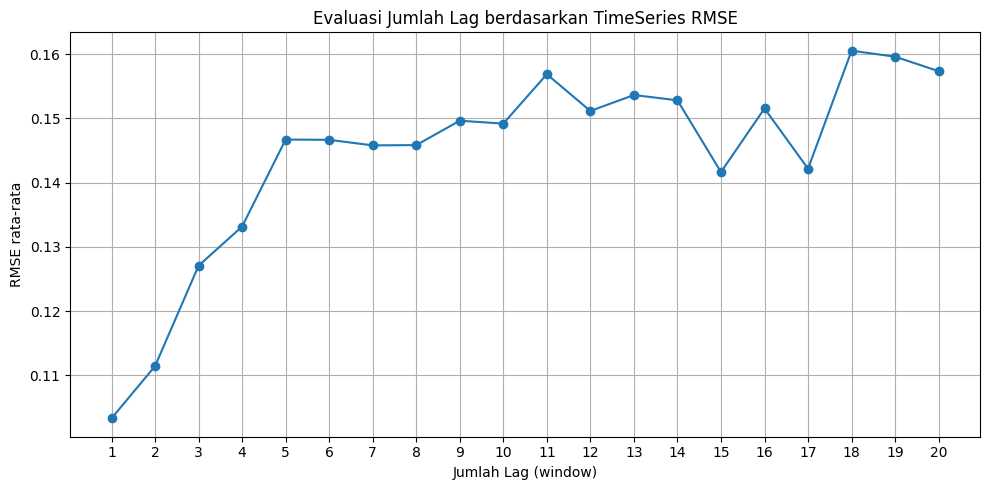

In [131]:
df_clean = preprocess_data(df)
df_clean = add_technical_indicators(df_clean)
df_clean = remove_outliers_iqr(df_clean, 'Close')
target_columns = ['Close']
feature_columns = target_columns + ['MA_5', 'MA_10', 'EMA_12', 'EMA_26', 'MACD', 'Momentum', 'Volatility_5', 'Price_Range', 'RSI']
results = grid_search_best_lag(df_clean, target_columns, feature_columns)
plot_grid_results(results)

In [132]:
best_window = min(results, key=lambda x: x[1])[0]
df_ml = create_multivariate_lag_features(df_clean, target_columns, feature_columns, best_window)
df_ml

,Close_lag_1,MA_5_lag_1,MA_10_lag_1,EMA_12_lag_1,EMA_26_lag_1,MACD_lag_1,Momentum_lag_1,Volatility_5_lag_1,Price_Range_lag_1,RSI_lag_1,Close
14,4500.0,4444.0,4481.0,4530.049536,4637.931625,-107.882089,100.0,76.354437,110.0,35.344828,4350.0
15,4350.0,4446.0,4444.0,4502.349607,4616.603356,-114.253749,-150.0,73.006849,150.0,31.297710,4400.0
16,4400.0,4420.0,4429.0,4486.603514,4600.558663,-113.955149,50.0,57.008771,110.0,29.687500,4340.0
17,4340.0,4398.0,4410.0,4464.049127,4581.258021,-117.208894,-60.0,63.403470,100.0,30.645161,4350.0
18,4350.0,4388.0,4404.0,4446.503107,4564.127798,-117.624690,10.0,66.858059,50.0,35.135135,4310.0
...,...,...,...,...,...,...,...,...,...,...,...
233,3910.0,3876.0,3830.0,3822.177081,3794.068384,28.108697,30.0,23.021729,40.0,73.913043,3790.0
234,3790.0,3864.0,3833.0,3817.226761,3793.767022,23.459739,-120.0,45.055521,180.0,62.962963,3840.0
235,3840.0,3856.0,3844.0,3820.730336,3797.191687,23.538649,50.0,45.055521,80.0,67.241379,4090.0
236,4090.0,3902.0,3879.0,3862.156438,3818.881192,43.275246,250.0,114.324101,130.0,79.012346,4270.0


In [133]:
x = df_ml.drop(columns=target_columns)
y = df_ml[target_columns]
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y)

In [134]:
model = MultiOutputRegressor(RandomForestRegressor(n_estimators=100, random_state=42))
model.fit(x_scaled, y_scaled)

MultiOutputRegressor(estimator=RandomForestRegressor(random_state=42))

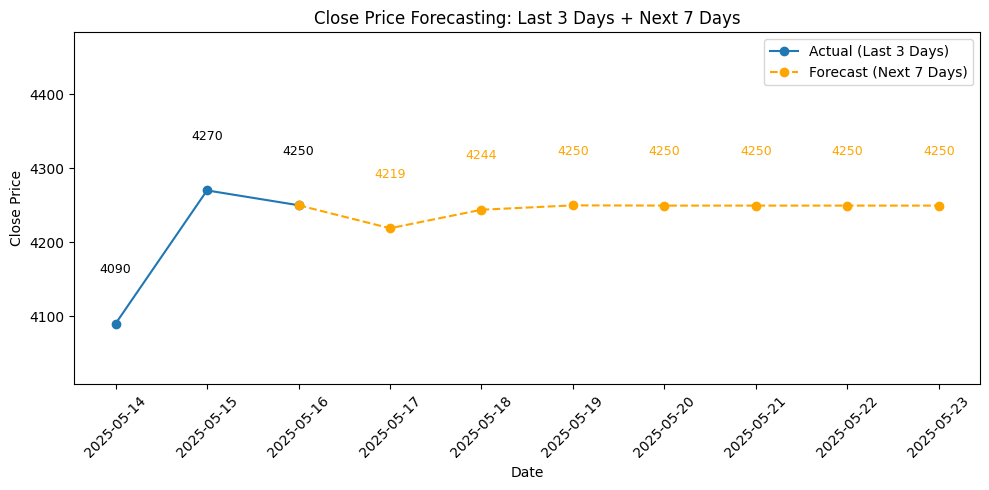

In [135]:
forecast = forecast_future(model, df_clean, scaler_x, scaler_y, target_columns, feature_columns, best_window, n_future=7)
visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3)

In [136]:
from sklearn.metrics import mean_absolute_percentage_error, r2_score

y_pred = model.predict(x_scaled)
y_pred_inv = scaler_y.inverse_transform(y_pred)
y_true_inv = scaler_y.inverse_transform(y_scaled)

mape = mean_absolute_percentage_error(y_true_inv, y_pred_inv)
r2 = r2_score(y_true_inv, y_pred_inv)
print(f"MAPE: {mape:.2%}")
print(f"R² Score: {r2:.3f}")


MAPE: 0.68%
R² Score: 0.993
